T5.15 (slide 55)

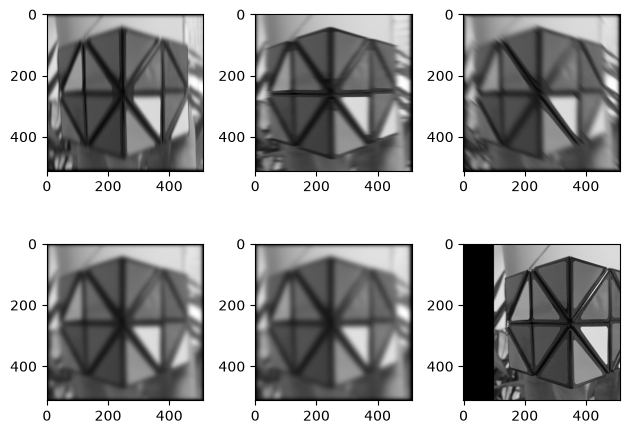

In [4]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt

# read image
img = np.mean(plt.imread('cube2.png'), axis=2)

# Mask definitions
masks = [
    np.array([[1, 2, 1]]).T / 4,
    np.array([[1, 2, 1]]) / 4,
    np.array([[1, 0, 0], [0, 2, 0], [0, 0, 1]]) / 4,
    0,
    np.ones([3, 3]) / 9,
    np.array([[0, 0, 1]])
]
masks[3] = sig.convolve(masks[0], masks[1])

# Apply masks 100 times
number = 100

# copy original img
results = [np.copy(img) for _ in masks]


for i, mask in enumerate(masks):
    for _ in range(number):
        results[i] = sig.convolve2d(results[i], mask, mode='same')

fig, axs = plt.subplots(2, 3)
axs = axs.flatten()

for ax, result in zip(axs, results):
    ax.imshow(result, cmap="gray")

fig.tight_layout()
plt.show()


1. blurring in x direction
2. blurring in y direction
3. blurring in diagonal direction
4. blurrs in both direction
5. uniform blurring (same weight everywhere) in both direction
6. shifting to the right

Claude making me an animation:

saved mask_animation.gif
saved mask_animation.mp4


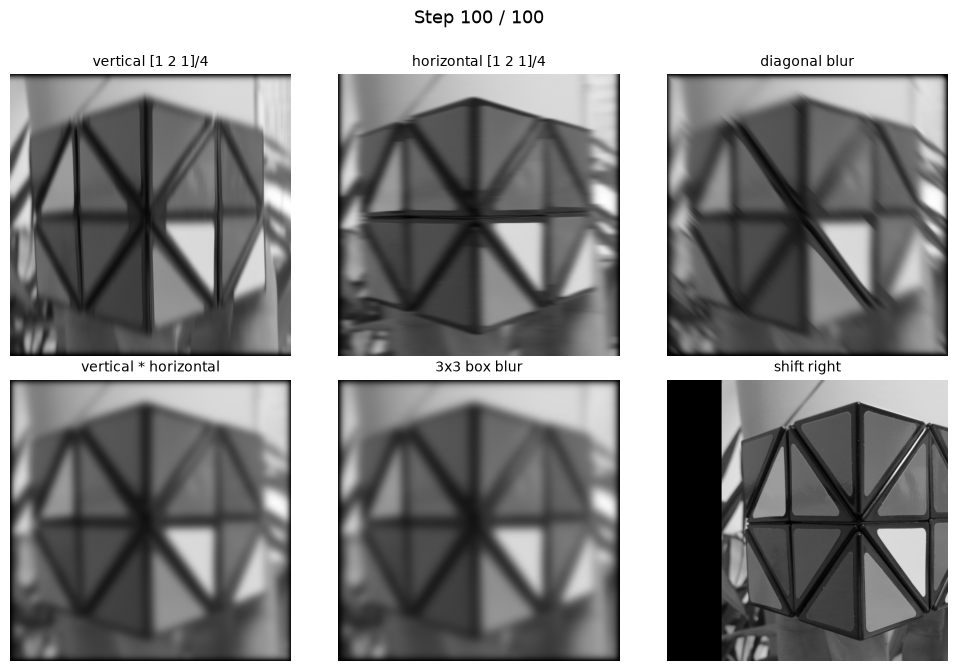

In [6]:
# import os
# import numpy as np
# from scipy import signal as sig
# import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter
#
# IMAGE_PATH = 'cube2.png'
# NUMBER = 100          # number of times each mask is applied
# FPS = 20
#
# # ---------- read image ----------
# if os.path.exists(IMAGE_PATH):
#     raw = plt.imread(IMAGE_PATH)
#     img = raw if raw.ndim == 2 else np.mean(raw[..., :3], axis=2)  # ignore alpha
# else:
#     # Fallback demo image (a simple shaded cube) so the script runs standalone
#     from PIL import Image, ImageDraw
#     im = Image.new('L', (300, 300), 255)
#     d = ImageDraw.Draw(im)
#     top   = [(150, 40), (250, 90), (150, 140), (50, 90)]
#     left  = [(50, 90), (150, 140), (150, 260), (50, 210)]
#     right = [(150, 140), (250, 90), (250, 210), (150, 260)]
#     for poly, c in ((top, 215), (left, 120), (right, 60)):
#         d.polygon(poly, fill=c, outline=0)
#     img = np.asarray(im, dtype=float) / 255
# img = img.astype(np.float32)
#
# # ---------- mask definitions ----------
# masks = [
#     np.array([[1, 2, 1]]).T / 4,
#     np.array([[1, 2, 1]]) / 4,
#     np.array([[1, 0, 0], [0, 2, 0], [0, 0, 1]]) / 4,
#     0,
#     np.ones([3, 3]) / 9,
#     np.array([[0, 0, 1]]),
# ]
# masks[3] = sig.convolve(masks[0], masks[1])
#
# titles = ['vertical [1 2 1]/4', 'horizontal [1 2 1]/4', 'diagonal blur',
#           'vertical * horizontal', '3x3 box blur', 'shift right']
#
# # ---------- precompute every step: frames[i][k] = mask i applied k times ----------
# frames = []
# for mask in masks:
#     cur = img.copy()
#     seq = [cur]
#     for _ in range(NUMBER):
#         cur = sig.convolve2d(cur, mask, mode='same').astype(np.float32)
#         seq.append(cur)
#     frames.append(seq)
#
# # ---------- figure ----------
# fig, axs = plt.subplots(2, 3, figsize=(10, 6.8))
# axs = axs.flatten()
# artists = []
# for ax, seq, t in zip(axs, frames, titles):
#     artists.append(ax.imshow(seq[0], cmap='gray', vmin=img.min(), vmax=img.max()))
#     ax.set_title(t, fontsize=10)
#     ax.axis('off')
# suptitle = fig.suptitle('', fontsize=13)
# fig.tight_layout(rect=(0, 0, 1, 0.95))
#
# HOLD = FPS  # hold first/last frame for ~1 s
# order = [0] * HOLD + list(range(NUMBER + 1)) + [NUMBER] * HOLD
#
# def update(k):
#     for art, seq in zip(artists, frames):
#         art.set_data(seq[k])
#     suptitle.set_text(f'Step {k} / {NUMBER}')
#     return artists + [suptitle]
#
# anim = FuncAnimation(fig, update, frames=order, interval=1000 / FPS, blit=False)
#
# anim.save('mask_animation.gif', writer=PillowWriter(fps=FPS), dpi=80)
# print('saved mask_animation.gif')
#
# try:
#     anim.save('mask_animation.mp4', writer=FFMpegWriter(fps=FPS, bitrate=2000), dpi=100)
#     print('saved mask_animation.mp4')
# except Exception as e:
#     print('mp4 skipped:', e)
#
# plt.show()  # uncomment for a live window

T5.16 (slide 58)

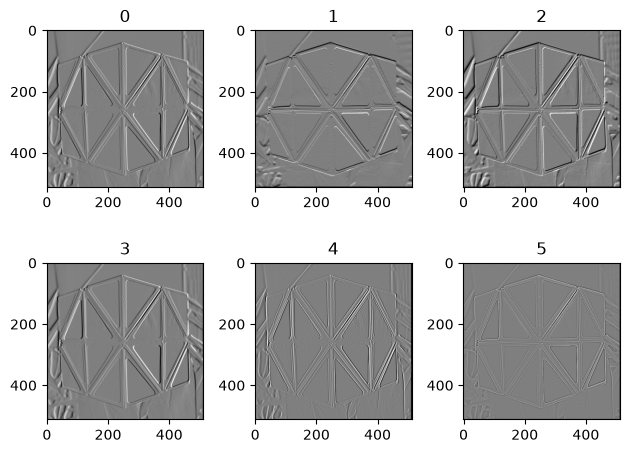

In [13]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt

# read image
img = np.mean(plt.imread('cube2.png'), axis=2)

# Mask definitions
more_masks = [
    np.array([[1, 0, -1]]),
    np.array([[1, 0, -1]]).T,
    np.array([[1, 0, 0], [0, 0, 0], [0, 0, -1]]),
    0,
    0,
    np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
]
more_masks[3] = sig.convolve(masks[1], more_masks[0])
more_masks[4] = sig.convolve(more_masks[0], more_masks[0])

# Apply masks 100 times
number = 1

# copy original img
results = [np.copy(img) for _ in more_masks]


for i, mask in enumerate(more_masks):
    for _ in range(number):
        results[i] = sig.convolve2d(results[i], mask, mode='same')

fig, axs = plt.subplots(2, 3)
axs = axs.flatten()

for i, (ax, result) in enumerate(zip(axs, results)):
    ax.set_title(i)
    ax.imshow(result, cmap="gray", vmin=-0.3, vmax=0.3)

fig.tight_layout()
plt.show()


1. Difference between two pixels (left, right) / calculating derivative in x direction
2. in y direction
3. diagonal derivative
4. smoothing in one direction (y) and derivative in another direction (x) (taking three pixels on the left and three pixels on the right to find derivative)
5. second derivative
6. edge detection

T5.17

In [12]:
import numpy as np
from scipy import signal as sig

Dx1 = np.hstack((np.zeros((3, 1)), np.array([[1, 0, -1]]).T, np.zeros((3, 1))))
Dy1 = np.copy(Dx1).T
laplace1 = sig.convolve2d(Dx1, Dx1, mode="full") + sig.convolve2d(Dy1, Dy1, mode="full")

Dx2 = np.array([
    [1, 2, 1],
    [0, 0, 0],
    [-1, -2, -1],
])
Dy2 = np.copy(Dx2).T
laplace2 = sig.convolve2d(Dx2, Dx2, mode="full") + sig.convolve2d(Dy2, Dy2, mode="full")

Dx3 = np.array([
    [3, 10, 3],
    [0, 0, 0],
    [-3, -10, -3],
])
Dy3 = np.copy(Dx3).T
laplace3 = sig.convolve2d(Dx3, Dx3, mode="full") + sig.convolve2d(Dy3, Dy3, mode="full")

print("Prewitt")
print(laplace1)

print("Sobel")
print(laplace2)

print("Scharr")
print(laplace3)

Prewitt
[[ 0.  0.  1.  0.  0.]
 [ 0.  0.  0.  0.  0.]
 [ 1.  0. -4.  0.  1.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.]]
Sobel
[[  2   4   4   4   2]
 [  4   0  -8   0   4]
 [  4  -8 -24  -8   4]
 [  4   0  -8   0   4]
 [  2   4   4   4   2]]
Scharr
[[  18   60  100   60   18]
 [  60    0 -120    0   60]
 [ 100 -120 -472 -120  100]
 [  60    0 -120    0   60]
 [  18   60  100   60   18]]


T5.18

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import signal as sig

def read_series(filenames,n):
  # print('reading:',filenames%0)
  img=plt.imread(filenames%0)
  s=img.shape
  imgstack=np.zeros([*s[:2],n])
  imgstack[:,:,0]=img
  for i in range(1,n):
    # print('reading:',filenames%i)
    imgstack[:,:,i]=plt.imread(filenames%i)
  return imgstack

def display_image_series(f,imgstack,cols=6):
  s=imgstack.shape
  for i in range(s[2]):
    ax=f.add_subplot(s[2]//cols,cols,i+1)
    ax.set_axis_off()
    plt.imshow(imgstack[:,:,i],cmap='gray')

def show_series():
  f=plt.figure(figsize=(12,4))
  imgstack=read_series('focus_series/fseries(%i).png',18)
  display_image_series(f,imgstack,9)
  #plt.savefig('focusseries.png', facecolor=(130./256,126./256,120./256),dpi=160)
  plt.show()

# show_series()


In [2]:

imgstack = read_series('focus_series/fseries(%i).png',18)

mean_img = np.mean(imgstack, axis=2)
# fig, ax = plt.subplots()
# ax.set_title("Mean image")
# ax.imshow(mean_img, cmap="gray")
# plt.show()

(2000, 1750)


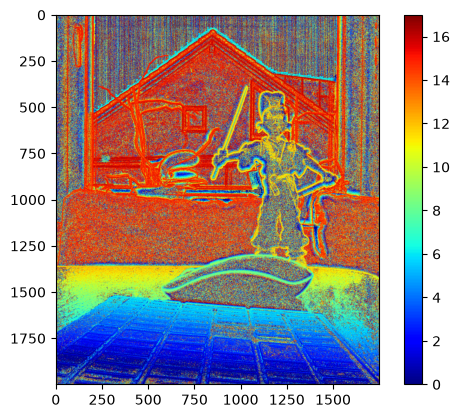

In [31]:
from scipy import signal as sig

Dx = np.array([
    [1, 2, 1],
    [0, 0, 0],
    [-1, -2, -1],
])
Dx = np.array([
    [3, 10, 3],
    [0, 0, 0],
    [-3, -10, -3],
])
Dy = np.copy(Dx).T
laplace_2d = sig.convolve2d(Dx, Dx, mode="full") + sig.convolve2d(Dy, Dy, mode="full")
laplace = np.stack((np.zeros((5, 5)), np.zeros((5, 5)), laplace_2d, np.zeros((5, 5)), np.zeros((5, 5))), axis=2)
laplace_response = sig.convolve(imgstack, laplace, mode="same")

img_index_map_max_laplace_response = np.argmax(np.abs(laplace_response), axis=2)

print(img_index_map_max_laplace_response.shape)

fig, ax = plt.subplots()
pos = ax.imshow(img_index_map_max_laplace_response, cmap="jet")
fig.colorbar(pos, ax=ax)
plt.show()


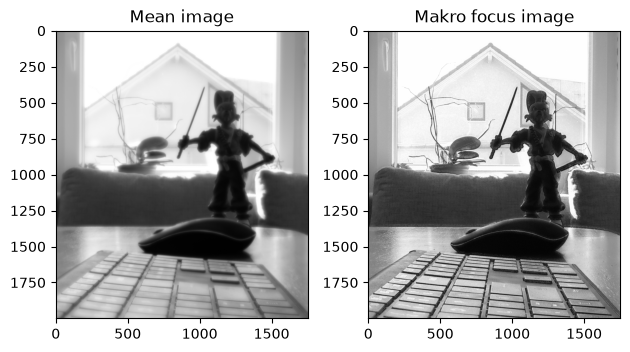

In [33]:
x, y = np.indices(img_index_map_max_laplace_response.shape)
result = imgstack[x, y, img_index_map_max_laplace_response]
# Or use: np.take_along_axis

fig, axs = plt.subplots(1, 2)
axs = axs.flatten()
axs[0].set_title("Mean image")
axs[0].imshow(np.mean(imgstack, axis=2), cmap="gray")

axs[1].set_title("Makro focus image")
axs[1].imshow(result, cmap="gray")

fig.tight_layout()
fig.savefig("result.png")
plt.show()